# MUC02 — Credit Pre-Screening Engine: Loan Intake Optimisation
**Calibo AI Academy · Path 2 · KLU Batch · Phase 2 — Supervised Learning Part 1**

**Team:** Batch 10 (4 members)

| Role | Member | Sections |
|---|---|---|
| Data Analyst | Naishadh Vytla | CBIM canvas (led, completed with all four), Step 5.1, notebook assembly, Triage web app |
| Insight Analyst | Raghunandan | Steps 5.2–5.3 |
| Model Builder | Pradeepthi | Steps 5.4–5.5 |
| Policy Synthesiser | Saketh | Steps 5.6–5.7 |

## CBIM Problem Canvas
*Completed as a team before any code was written.*

| Canvas element | Our answer |
|---|---|
| **Situation (S)** | A mid-size private bank's retail lending unit receives about 3,000 unsecured personal loan applications a month from across India. Every application gets a manual credit review that takes an analyst about 25 minutes. |
| **Complication (C)** | Close to half the applications are declined, and many of those are obvious within the first minute (a very low credit score, or EMIs that already take most of the income). The bank spends analyst hours on clear-cut cases. Applicants who deserve a careful review wait longer, and the unit cannot handle more volume without hiring. |
| **Question (Q)** | Which applications can be taken out of the manual queue and auto-declined, at what model confidence, so that no more than 5% of auto-declines are applicants the credit team would have approved? And how many applications and analyst hours does that free each month? |
| **SSOT** | `MUC02_Credit_PreScreening_Dataset.csv`: 12,000 applications, Apr–Sep 2026, one row per application. Every team member works from this one file and from one cleaning log (Step 5.1). The `decision` column is **the credit team's past judgement, not whether the customer repaid**, so the model learns to copy analyst decisions, including any bias in them. |
| **Success definition** | The success measure is not accuracy. It is a threshold where **≤ 5% of auto-declined applications were actually approved** by analysts, stated as applications and analyst hours freed per month. We also need a named group the model must not decide for, and no widening of the gender gap. |
| **Primary stakeholder** | The **Credit Policy Analyst**, who has to defend the proposal to the **Head of Retail Lending**. Also affected: the **credit analysts**, whose queue changes, and the **applicants**, above all the creditworthy ones an automatic decline would turn away. |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score, ConfusionMatrixDisplay)

# One chart style for the whole team
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cec8", "grid.color": "#ebe9e4",
                                     "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.float_format", "{:,.2f}".format)

def label_bars(ax, fmt="{:.1f}%"):
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=9, color=INK, xytext=(0, 2),
                        textcoords="offset points")

---
## Step 5.1 — Load, inspect and clean
*Built by: Naishadh Vytla — Data Analyst*

In [2]:
from pathlib import Path
# Works whether the CSV sits beside the notebook (Colab / Jupyter) or in the repo's data/ folder
CSV = next(p for p in ["MUC02_Credit_PreScreening_Dataset.csv", "../data/MUC02_Credit_PreScreening_Dataset.csv",
                       "data/MUC02_Credit_PreScreening_Dataset.csv"] if Path(p).exists())
df = pd.read_csv(CSV)
print("Shape:", df.shape)
df.info()

Shape: (12000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    

In [3]:
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nOverall approval rate: {(df['decision'] == 'Approved').mean():.1%}")
df["decision"].value_counts()

Missing values:
monthly_income     441
credit_score      1039
dtype: int64

Overall approval rate: 52.9%


decision
Approved    6353
Declined    5647
Name: count, dtype: int64

The target is reasonably balanced: **52.9% approved, 47.1% declined**. Accuracy will not be badly misleading, but it still is not the number the bank cares about. What matters is how many good applicants an automatic decline turns away.

Two columns have gaps: `monthly_income` (441) and `credit_score` (1,039). We look at each one before deciding what to do.

In [4]:
# Issue 1 — where is income missing?
miss_inc = (df.assign(income_missing=df["monthly_income"].isna())
              .groupby("employment_type")["income_missing"].agg(["sum", "mean"])
              .rename(columns={"sum": "missing_rows", "mean": "share_missing"}))
miss_inc

,missing_rows,share_missing
employment_type,,
Business Owner,227,0.13
Gig / Contract,11,0.01
Salaried,49,0.01
Self-Employed Professional,154,0.11


In [5]:
# Issue 2 — who has a blank credit score?
blank = df[df["credit_score"].isna()]
print("Rows with blank credit score:", len(blank))
print("credit_history_months for those rows:", blank["credit_history_months"].unique())
print("Rows with credit_history_months == 0:", (df["credit_history_months"] == 0).sum())
print(f"Median age — blank score: {blank['age'].median():.0f}, scored: {df.loc[df['credit_score'].notna(), 'age'].median():.0f}")

Rows with blank credit score: 1039
credit_history_months for those rows: [0]
Rows with credit_history_months == 0: 1039
Median age — blank score: 29, scored: 33


In [6]:
# Issue 3 — implausible monthly incomes
print(df["monthly_income"].describe())
high = df[df["monthly_income"] > 600_000]
print(f"\n{len(high)} rows above ₹6,00,000/month — employment types:", high["employment_type"].unique())
high[["application_id", "employment_type", "monthly_income", "existing_emi", "proposed_emi"]]

count      11,559.00
mean       60,314.86
std        48,890.83
min        12,000.00
25%        33,500.00
50%        50,500.00
75%        74,750.00
max     1,656,000.00
Name: monthly_income, dtype: float64

12 rows above ₹6,00,000/month — employment types: <StringArray>
['Salaried']
Length: 1, dtype: str


,application_id,employment_type,monthly_income,existing_emi,proposed_emi
300,APP100301,Salaried,"1,254,000.00",0.00,"6,600.00"
589,APP100590,Salaried,"1,068,000.00","13,500.00","14,000.00"
1467,APP101468,Salaried,"1,656,000.00","16,500.00","44,400.00"
1848,APP101849,Salaried,"984,000.00",0.00,"17,100.00"
2488,APP102489,Salaried,"972,000.00",0.00,"10,600.00"
2493,APP102494,Salaried,"1,212,000.00","23,500.00","14,000.00"
4010,APP104011,Salaried,"900,000.00","4,000.00","19,800.00"
4898,APP104899,Salaried,"870,000.00","4,500.00","15,000.00"
7426,APP107427,Salaried,"690,000.00",0.00,"16,600.00"
8381,APP108382,Salaried,"618,000.00",0.00,"14,400.00"


In [7]:
# --- Apply cleaning decisions ---
clean = df.copy()

# (a) Annual income keyed as monthly: divide by 12
clean["income_fixed_annual"] = (clean["monthly_income"] > 600_000).astype(int)
clean.loc[clean["income_fixed_annual"] == 1, "monthly_income"] /= 12

# (b) Missing income: fill with the median for that employment type (computed after fix a)
clean["income_was_missing"] = clean["monthly_income"].isna().astype(int)
emp_median = clean.groupby("employment_type")["monthly_income"].median()
clean["monthly_income"] = clean["monthly_income"].fillna(clean["employment_type"].map(emp_median))

# (c) Blank credit score = new to credit: keep the rows, flag them (done in Step 5.3 as is_ntc)
clean["approved"] = (clean["decision"] == "Approved").astype(int)

print("Median income used for filling:\n", emp_median)
print("\nRemaining nulls:\n", clean.isna().sum()[clean.isna().sum() > 0])
print("Rows kept:", len(clean))

Median income used for filling:
 employment_type
Business Owner               69,500.00
Gig / Contract               28,000.00
Salaried                     50,000.00
Self-Employed Professional   75,000.00
Name: monthly_income, dtype: float64

Remaining nulls:
 credit_score    1039
dtype: int64
Rows kept: 12000


### Cleaning log

| # | Issue | What we found | Decision | Why a bank reviewer would agree |
|---|---|---|---|---|
| 1 | **12 incomes above ₹6 lakh/month** | All 12 are **Salaried**, with values like ₹9–16.5 lakh. Their EMIs and loan sizes look like those of ordinary ₹50K–1.4L earners. | **Divided by 12.** Flag kept in `income_fixed_annual`. | These are annual salaries typed into a monthly field. Left as they are, they make FOIR look tiny and these applicants look far safer than they are. Dividing keeps the rows and makes the figures plausible. |
| 2 | **441 missing incomes** | Concentrated in **Business Owner (13.0%)** and **Self-Employed Professional (10.8%)**. Under 1% for Salaried and Gig. | **Filled with the median income for that employment type** (Business Owner ₹69.5K, Self-Employed ₹75K, Salaried ₹50K, Gig ₹28K). Flag kept in `income_was_missing`. | Incomes differ a lot by employment type, so an overall median would under-state self-employed incomes and over-state gig incomes. Missing income is itself a self-employed pattern (no payslip to declare), so we keep the flag instead of hiding it. |
| 3 | **1,039 blank credit scores** | `credit_history_months` is **0 for every one of them**, and exactly these 1,039 applicants have zero history. They are younger (median age 29 vs 33). | **Kept all rows.** Flagged as new to credit (`is_ntc`, Step 5.3). The score is filled with the median only inside the model (Step 5.4). | They are not data errors. They are **new-to-credit applicants, 8.7% of all applications**. Dropping them would remove a real customer group, mostly young first-time borrowers, and hide the group the model handles worst. |

**No rows were dropped.** The cleaned dataset still has all 12,000 applications.

---
## Step 5.2 — What drives approval today?
*Built by: Raghunandan — Insight Analyst*

In [8]:
score_bins   = [0, 600, 650, 700, 750, 800, 1000]
score_labels = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]
clean["score_band"] = (pd.cut(clean["credit_score"], bins=score_bins, labels=score_labels, right=False)
                         .cat.add_categories("No score").fillna("No score"))

by_score = clean.groupby("score_band", observed=False)["approved"].agg(applications="size", approval_rate="mean")
by_score["approval_rate"] *= 100
by_score

,applications,approval_rate
score_band,,
Below 600,246,2.03
600–649,933,3.22
650–699,2529,32.50
700–749,3377,54.37
750–799,2526,77.20
800+,1350,85.19
No score,1039,53.90


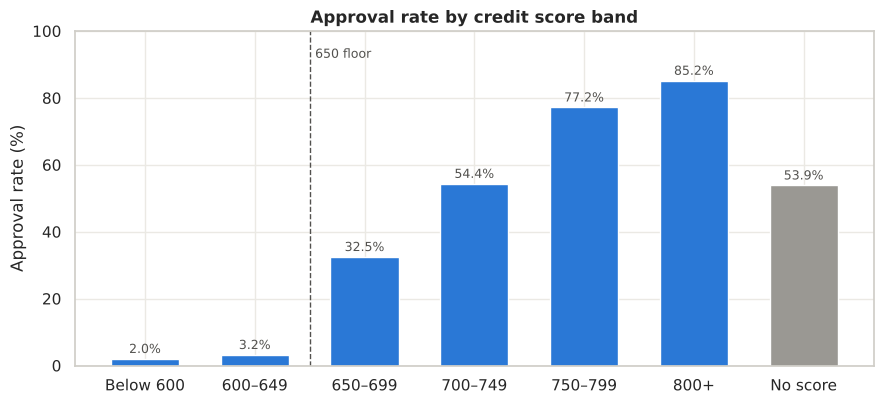

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [BLUE] * 6 + [GREY]
ax.bar(by_score.index.astype(str), by_score["approval_rate"], color=colors, width=0.62)
ax.axvline(1.5, color=INK, ls="--", lw=1)
ax.text(1.55, 92, "650 floor", color=INK, fontsize=9)
label_bars(ax)
ax.set(title="Approval rate by credit score band", ylabel="Approval rate (%)", xlabel="", ylim=(0, 100))
plt.tight_layout(); plt.show()

,applications,approval_rate
employment_type,,
Salaried,7057,58.37
Business Owner,1749,51.17
Self-Employed Professional,1428,50.56
Gig / Contract,1766,34.94


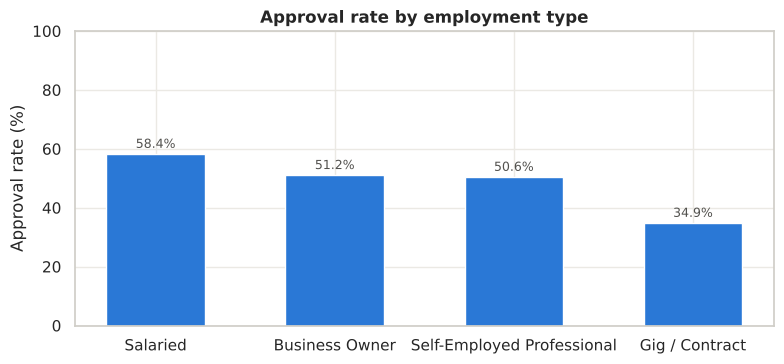

In [10]:
by_emp = (clean.groupby("employment_type")["approved"].agg(applications="size", approval_rate="mean")
              .sort_values("approval_rate", ascending=False))
by_emp["approval_rate"] *= 100
display(by_emp)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_emp.index, by_emp["approval_rate"], color=BLUE, width=0.55)
label_bars(ax)
ax.set(title="Approval rate by employment type", ylabel="Approval rate (%)", xlabel="", ylim=(0, 100))
plt.tight_layout(); plt.show()

**What this means for the credit team**

- **The bank has an unwritten credit score floor at 650.** Below 600, only **2.0%** of applications are approved; at 600–649, **3.2%**. Just across the line, at 650–699, approval jumps to **32.5%**, a tenfold increase. Above 750, about 4 in 5 are approved (77.2% and 85.2%). No written policy says so, but analysts almost never approve below 650. That is a rule a pre-screener can apply with confidence, and it is exactly the kind of "decided in the first minute" case the Head of Retail Lending described.
- **New-to-credit applicants are approved 53.9% of the time**, almost the same as the overall rate. With no bureau score, analysts are clearly using judgement (income, job, loan size), not a rule. This group will be hard for a model to call.
- **Gig / Contract workers are approved least, at 34.9%**, against **58.4% for Salaried**. The label alone does not explain this. Gig workers have the lowest incomes (median ₹28K) and less stable earnings, which feeds straight into affordability (Step 5.3).

---
## Step 5.3 — Engineer the affordability features
*Built by: Raghunandan — Insight Analyst*

In [11]:
clean["foir"]           = (clean["existing_emi"] + clean["proposed_emi"]) / clean["monthly_income"]
clean["loan_to_income"] = clean["loan_amount"] / (clean["monthly_income"] * 12)
clean["is_ntc"]         = clean["credit_score"].isna().astype(int)

print(clean[["foir", "loan_to_income"]].describe().T)
print(f"\nNew-to-credit applicants: {clean['is_ntc'].sum():,} ({clean['is_ntc'].mean():.1%})")

                   count  mean  std  min  25%  50%  75%  max
foir           12,000.00  0.36 0.21 0.00 0.21 0.32 0.45 3.39
loan_to_income 12,000.00  0.53 0.23 0.01 0.35 0.52 0.70 2.78

New-to-credit applicants: 1,039 (8.7%)


,applications,approval_rate
foir_band,,
Below 30%,5491,65.47
30–40%,2497,58.99
40–50%,1766,47.85
50–55%,531,32.39
Above 55%,1715,15.63


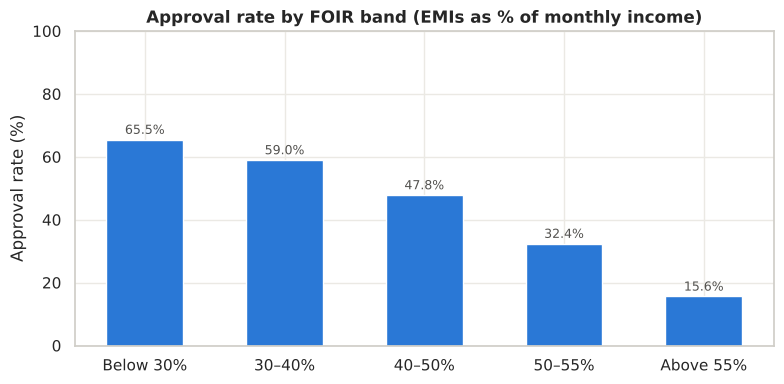

In [12]:
foir_bins   = [0, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
clean["foir_band"] = pd.cut(clean["foir"], bins=foir_bins, labels=foir_labels, right=False)

by_foir = clean.groupby("foir_band", observed=False)["approved"].agg(applications="size", approval_rate="mean")
by_foir["approval_rate"] *= 100
display(by_foir)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_foir.index.astype(str), by_foir["approval_rate"], color=BLUE, width=0.55)
label_bars(ax)
ax.set(title="Approval rate by FOIR band (EMIs as % of monthly income)",
       ylabel="Approval rate (%)", xlabel="", ylim=(0, 100))
plt.tight_layout(); plt.show()

**What this means for the credit team**

- **FOIR** is the share of monthly income that would go to EMIs once the new loan is added. Approval falls steadily as it rises: **65.5%** below 30%, **59.0%** at 30–40%, **47.8%** at 40–50%. Past 50% it **collapses**: **32.4%** at 50–55% and only **15.6%** above 55%.
- **The sharpest drop is across 50%.** Approval falls 15 points between the 40–50% and 50–55% bands, then halves again above 55%.
- **Proposed policy:** a **FOIR limit of 50%**, with 50–55% treated as an exception band that needs analyst sign-off, and above 55% as a near-automatic decline. That matches what analysts already do.
- 1,715 applicants (14.3%) are already above 55% FOIR. They are the second big group of "first-minute" declines, after sub-650 scores.
- `loan_to_income` measures the loan size against annual income. `is_ntc` makes sure the model knows which credit scores are real and which are filled.

---
## Step 5.4 — Build the logistic regression pre-screener
*Built by: Pradeepthi — Model Builder*

Target: **1 = Declined**, 0 = Approved. The model predicts declines, because the bank wants to auto-decline safely.
Features as specified. `application_id`, `application_date`, `city`, `gender` and `decision` are **excluded**.

In [13]:
y = (clean["decision"] == "Declined").astype(int)

num_features = ["credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
                "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"]
cat_features = ["employment_type", "loan_purpose"]

X = clean[num_features + cat_features].copy()
X["credit_score"] = X["credit_score"].fillna(clean["credit_score"].median())   # is_ntc marks the filled rows

assert not {"gender", "city", "decision", "application_id", "application_date"} & set(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])),
    ("logreg", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Test set: {len(y_test):,} applications")
print(f"Accuracy:             {accuracy_score(y_test, y_pred):.1%}")
print(f"ROC-AUC:              {roc_auc_score(y_test, y_proba):.3f}")
print(f"Precision (Declined): {precision_score(y_test, y_pred):.1%}")
print(f"Recall (Declined):    {recall_score(y_test, y_pred):.1%}")

Test set: 2,400 applications
Accuracy:             79.1%
ROC-AUC:              0.867
Precision (Declined): 79.1%
Recall (Declined):    75.5%


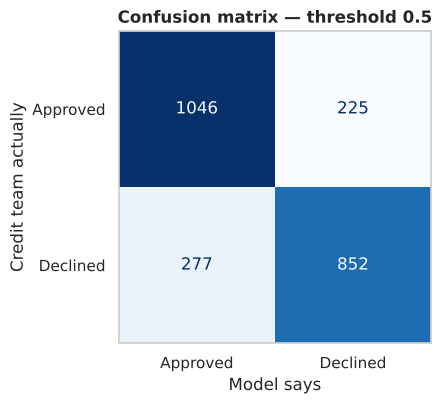

Good customers wrongly declined (FP): 225   Declines missed (FN): 277

Accuracy — scored applicants: 81.2%  (n=2197)
Accuracy — new to credit:     56.7%  (n=203)


In [14]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Approved", "Declined"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Confusion matrix — threshold 0.5", xlabel="Model says", ylabel="Credit team actually")
ax.grid(False)
plt.tight_layout(); plt.show()
print(f"Good customers wrongly declined (FP): {fp}   Declines missed (FN): {fn}")

ntc_test = X_test["is_ntc"] == 1
print(f"\nAccuracy — scored applicants: {accuracy_score(y_test[~ntc_test], y_pred[~ntc_test]):.1%}  (n={(~ntc_test).sum()})")
print(f"Accuracy — new to credit:     {accuracy_score(y_test[ntc_test], y_pred[ntc_test]):.1%}  (n={ntc_test.sum()})")

Five largest coefficients (scaled features; + pushes towards DECLINE):


,coefficient
foir,1.22
credit_score,-1.01
delinquencies_24m,0.98
Employment: Gig / Contract,0.62
Employment: Salaried,-0.44


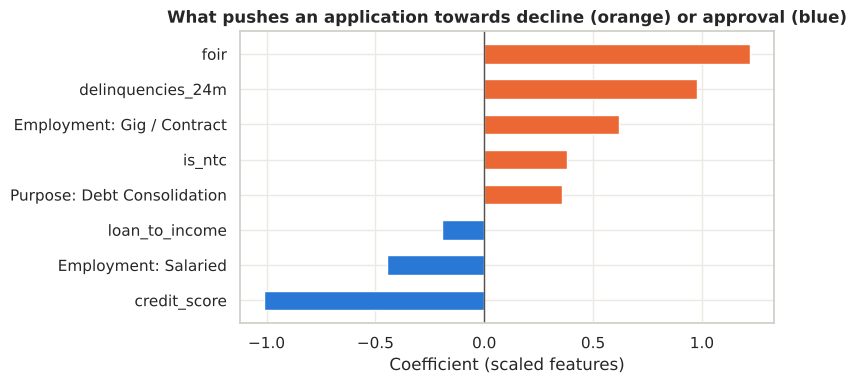

In [15]:
feat_names = (pd.Index(model.named_steps["prep"].get_feature_names_out())
              .str.replace("num__", "").str.replace("cat__employment_type_", "Employment: ")
              .str.replace("cat__loan_purpose_", "Purpose: "))
coefs = pd.Series(model.named_steps["logreg"].coef_[0], index=feat_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print("Five largest coefficients (scaled features; + pushes towards DECLINE):")
display(top.head(5).to_frame("coefficient"))

plot = top.head(8).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(plot.index, plot.values, color=[ORANGE if v > 0 else BLUE for v in plot.values], height=0.55)
ax.axvline(0, color=INK, lw=1)
ax.set(title="What pushes an application towards decline (orange) or approval (blue)",
       xlabel="Coefficient (scaled features)")
plt.tight_layout(); plt.show()

**The confusion matrix in business language** (test set of 2,400 applications, default cut-off 0.5)

- Accuracy is **79.1%** (ROC-AUC 0.867), but accuracy is not the number the bank should look at.
- **225 applicants the credit team approved would have been declined by the model.** These are creditworthy customers turned away. At 3,000 applications a month, that would be roughly **280 good customers a month**.
- **277 applications the team declined were let through** to manual review. That costs analyst time but does no harm to the customer, because an analyst still decides.
- Of the applications the model calls "Declined", **79.1%** really were declined (precision). It catches **75.5%** of all declines (recall).
- **The model is much weaker on new-to-credit applicants: 56.7% accurate, against 81.2% for scored applicants.** For people with no bureau history it is barely better than a coin toss.

**Reading the coefficients like a credit analyst** (features are scaled, so sizes can be compared directly)

1. **FOIR (+1.22), the strongest driver.** The more of an applicant's income already goes to EMIs, the more likely a decline. This is the affordability cliff from Step 5.3.
2. **Credit score (−1.01).** A higher score pulls strongly towards approval, which matches the 650 floor in Step 5.2.
3. **Late payments in the last 24 months (+0.98).** Every additional late or missed repayment pushes the application further towards decline. Analysts weigh repayment behaviour almost as heavily as the score itself.
4. **Gig / Contract worker (+0.62).** With every other factor held equal, a gig worker is still more likely to be declined. The credit team treats unstable income as a risk in itself.
5. **Salaried (−0.44).** A salaried job pulls towards approval, because income is stable and verifiable.

Further down: being **new to credit (+0.38)** and borrowing for **Debt Consolidation (+0.36)** both push towards decline. The model has learned the same policy we found by hand in Steps 5.2 and 5.3, which gives us confidence it is copying real credit policy and not noise.

---
## Step 5.5 — Set the auto-decline threshold
*Built by: Pradeepthi — Model Builder*

The bank will auto-decline only when the model is very confident. **Risk limit: no more than 5% of auto-declined applications may be ones the credit team would have approved.**

In [16]:
rows = []
for t in [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]:
    auto = y_proba >= t
    rows.append({
        "threshold": t,
        "pct_auto_declined": auto.mean() * 100,
        "pct_wrongly_declined": (y_test[auto] == 0).mean() * 100,      # of auto-declines, actually approved
        "good_customers_wrongly_declined": int((y_test[auto] == 0).sum()),
        "pct_of_all_declines_caught": auto[y_test == 1].mean() * 100,
    })
thr = pd.DataFrame(rows)
thr["meets_5pct_rule"] = thr["pct_wrongly_declined"] <= 5
thr

,threshold,pct_auto_declined,pct_wrongly_declined,good_customers_wrongly_declined,pct_of_all_declines_caught,meets_5pct_rule
0,0.50,44.88,20.89,225,75.47,False
1,0.60,37.62,16.83,152,66.52,False
2,0.70,30.75,12.06,89,57.48,False
3,0.80,23.46,7.10,40,46.32,False
4,0.85,19.67,5.93,28,39.33,False
5,0.90,15.21,4.66,17,30.82,True
6,0.95,10.00,2.08,5,20.81,True


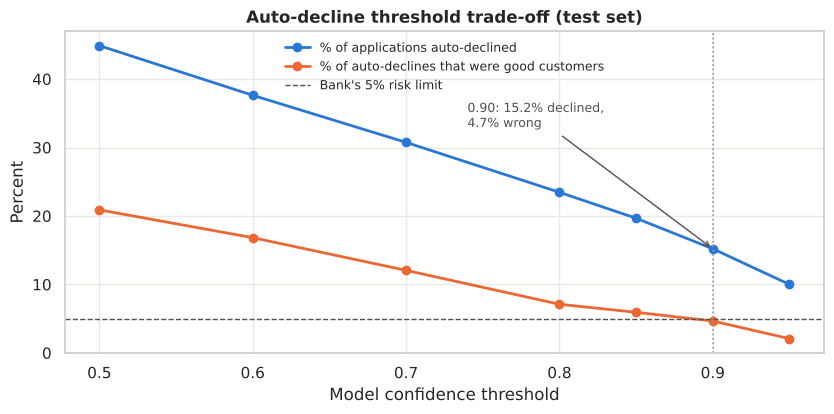

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(thr["threshold"], thr["pct_auto_declined"], marker="o", lw=2, color=BLUE, label="% of applications auto-declined")
ax.plot(thr["threshold"], thr["pct_wrongly_declined"], marker="o", lw=2, color=ORANGE, label="% of auto-declines that were good customers")
ax.axhline(5, color=INK, ls="--", lw=1, label="Bank's 5% risk limit")
ax.axvline(0.90, color=GREY, ls=":", lw=1.2)
ax.annotate("0.90: 15.2% declined,\n4.7% wrong", xy=(0.90, 15.2), xytext=(0.74, 33),
            fontsize=9, color=INK, arrowprops=dict(arrowstyle="->", color=INK))
ax.set(title="Auto-decline threshold trade-off (test set)", xlabel="Model confidence threshold", ylabel="Percent")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [18]:
# Choose the lowest threshold that meets the 5% rule (= most applications auto-declined)
chosen = thr.loc[thr["meets_5pct_rule"], "threshold"].min()
row = thr.set_index("threshold").loc[chosen]

MONTHLY_APPS, MINUTES_PER_REVIEW = 3000, 25
apps_month  = MONTHLY_APPS * row["pct_auto_declined"] / 100
hours_month = apps_month * MINUTES_PER_REVIEW / 60
wrong_month = apps_month * row["pct_wrongly_declined"] / 100

print(f"Chosen threshold: {chosen}")
print(f"Auto-declined: {row['pct_auto_declined']:.1f}% → ~{apps_month:.0f} applications/month")
print(f"Analyst time freed: ~{hours_month:.0f} hours/month")
print(f"Wrongly declined: {row['pct_wrongly_declined']:.1f}% of auto-declines → ~{wrong_month:.0f} good customers/month")

Chosen threshold: 0.9
Auto-declined: 15.2% → ~456 applications/month
Analyst time freed: ~190 hours/month
Wrongly declined: 4.7% of auto-declines → ~21 good customers/month


In [19]:
# Refinement: never let the model decide for new-to-credit applicants
auto     = y_proba >= chosen
auto_ntc = auto & ntc_test.values
safe     = auto & ~ntc_test.values

print(f"NTC applicants in the auto-decline lane at {chosen}: {auto_ntc.sum()} "
      f"— of whom {(y_test[auto_ntc] == 0).sum()} were actually approved")
print(f"\nWith NTC routed to analysts:")
print(f"  Auto-declined: {safe.mean():.1%} of applications → ~{MONTHLY_APPS * safe.mean():.0f}/month, "
      f"~{MONTHLY_APPS * safe.mean() * MINUTES_PER_REVIEW / 60:.0f} analyst hours")
print(f"  Wrongly declined: {(y_test[safe] == 0).mean():.1%} of auto-declines")

NTC applicants in the auto-decline lane at 0.9: 12 — of whom 6 were actually approved

With NTC routed to analysts:
  Auto-declined: 14.7% of applications → ~441/month, ~184 analyst hours
  Wrongly declined: 3.1% of auto-declines


In [20]:
# With new-to-credit applicants always routed to analysts, does the 5% rule allow a lower threshold?
rows = []
for t in [0.80, 0.85, 0.90, 0.95]:
    lane = (y_proba >= t) & ~ntc_test.values
    share, wrong = lane.mean(), (y_test[lane] == 0).mean()
    rows.append({"threshold": t, "pct_auto_declined": share * 100, "pct_wrongly_declined": wrong * 100,
                 "apps_per_month": MONTHLY_APPS * share, "hours_per_month": MONTHLY_APPS * share * MINUTES_PER_REVIEW / 60,
                 "good_customers_per_month": MONTHLY_APPS * share * wrong})
thr_ntc = pd.DataFrame(rows)
thr_ntc["meets_5pct_rule"] = thr_ntc["pct_wrongly_declined"] <= 5
thr_ntc

,threshold,pct_auto_declined,pct_wrongly_declined,apps_per_month,hours_per_month,good_customers_per_month,meets_5pct_rule
0,0.80,22.58,6.09,677.50,282.29,41.25,False
1,0.85,19.04,4.81,571.25,238.02,27.50,True
2,0.90,14.71,3.12,441.25,183.85,13.75,True
3,0.95,9.88,1.69,296.25,123.44,5.00,True


**The threshold decision**

- **We recommend 0.90.** It is the lowest threshold in the table that keeps wrong declines inside the 5% limit (**4.7%**), so it auto-declines as many applications as the rule allows. At 0.85, wrong declines are 5.9%, which breaks the rule. At the default 0.5, **one in five** auto-declines (20.9%) would be a good customer.
- **The monthly business case:** at 0.90 the model auto-declines **15.2%** of applications. That is **about 456 of the 3,000 applications a month, freeing about 190 analyst hours** (456 × 25 minutes), at the cost of roughly **21 good customers a month** wrongly declined.
- **Why the number is modest, and why that is fine:** a single strict lane catches only **30.8% of all declines**. The rest still go to analysts, who would have declined them anyway. We are not trying to automate the credit team. We are removing the clearest cases at very low risk, as a first step the bank can extend once it trusts the model.
- **Refinement: keep new-to-credit applicants with analysts.** At 0.90, the 12 NTC applicants in the auto-decline lane on the test set include **6 the bank approved, a 50% error rate**. Routing every NTC applicant to a human costs only half a point of volume (**14.7% auto-declined, about 441 applications and 184 hours a month**) and brings wrong declines down to **3.1%**, comfortably inside the limit. **This is the version we recommend going live with.**
- **Why not go lower once NTC applicants are excluded?** With NTC routed to analysts, **0.85 also passes the rule (4.8%)** and would free about **238 hours** a month instead of 184. But 4.8% is a 0.2-point margin measured on 2,400 test applications, and it doubles the good customers turned away (about 27 a month instead of 14). For a first launch we keep **0.90**: it sits well inside the limit, and the bank can lower it once live results confirm the error rate.

---
## Step 5.6 — Fairness check
*Built by: Saketh — Policy Synthesiser*

Gender was **not** used as a feature. We check whether the outcomes are fair anyway.

gender,Female,Male,"gap (M − F, pts)"
All,50.40,54.10,3.70
Business Owner,51.60,51.10,-0.60
Gig / Contract,34.60,35.20,0.50
Salaried,56.80,59.10,2.30
Self-Employed Professional,47.60,52.00,4.30


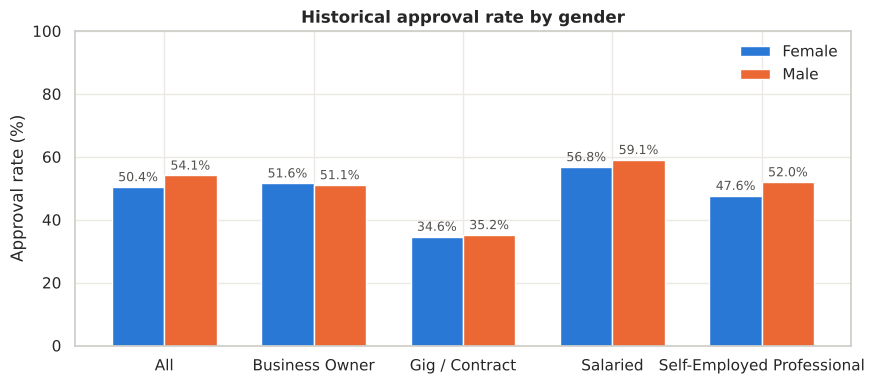

In [21]:
# (1) Historical approval rate by gender — overall and within employment type
overall = clean.groupby("gender")["approved"].mean().mul(100).rename("All")
within  = clean.pivot_table(index="employment_type", columns="gender", values="approved").mul(100)
gender_tbl = pd.concat([overall.to_frame().T, within])
gender_tbl["gap (M − F, pts)"] = gender_tbl["Male"] - gender_tbl["Female"]
display(gender_tbl.round(1))

ax = gender_tbl[["Female", "Male"]].plot(kind="bar", figsize=(9, 4), color=[BLUE, ORANGE], width=0.7, rot=0)
label_bars(ax)
ax.set(title="Historical approval rate by gender", ylabel="Approval rate (%)", xlabel="", ylim=(0, 100))
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [22]:
# (2) Income and job mix by gender
mix = pd.DataFrame({
    "median_monthly_income": clean.groupby("gender")["monthly_income"].median(),
    "pct_gig_contract": clean.groupby("gender")["employment_type"].apply(lambda s: (s == "Gig / Contract").mean() * 100),
    "applications": clean["gender"].value_counts(),
})
mix

,median_monthly_income,pct_gig_contract,applications
gender,,,
Female,"45,000.00",21.37,3795
Male,"55,000.00",11.64,8205


In [23]:
# (3) Model auto-decline rate by gender at the chosen threshold
test_gender = clean.loc[X_test.index, "gender"]
fair = pd.DataFrame({
    "actual_approval_rate_%":   (y_test == 0).groupby(test_gender).mean() * 100,
    f"auto_decline_rate_%_at_{chosen}": pd.Series(y_proba >= chosen, index=X_test.index).groupby(test_gender).mean() * 100,
    "auto_decline_rate_%_ntc_excluded": pd.Series(safe, index=X_test.index).groupby(test_gender).mean() * 100,
})
fair.round(1)

,actual_approval_rate_%,auto_decline_rate_%_at_0.9,auto_decline_rate_%_ntc_excluded
gender,,,
Female,50.30,15.60,15.10
Male,54.20,15.00,14.50


**Fairness position**

- **There is a gap in the historical data:** male applicants were approved **54.1%** of the time and female applicants **50.4%**, a 3.7-point gap.
- **Most of it comes from income and job mix.** Female applicants have a lower median income (**₹45K vs ₹55K**) and are almost **twice as likely to be gig workers (21.4% vs 11.6%)**, the group approved least. Within Gig / Contract and Business Owner the gap is **under 1 point**. A gap remains within Salaried (2.3 pts) and Self-Employed (4.3 pts), which we should keep watching.
- **The model leaves the gap unchanged and does not widen it.** At 0.90 it auto-declines **15.6% of female and 15.0% of male** applicants in the test set, and **15.1% vs 14.5%** in the recommended lane with new-to-credit applicants routed to analysts. Either way the difference is about half a point.
- **Gender should never be a feature in a credit model.** A bank could not defend it. **But leaving it out does not fully solve the problem.** Income, employment type and FOIR are partly stand-ins for gender, so a model can reproduce a gap without ever seeing the column. The bank should **report approval and auto-decline rates by gender every month** after launch and investigate if the gap grows.

---
## Step 5.7 — Credit Policy Briefing
*Built by: Saketh — Policy Synthesiser, drawing on Steps 5.1 (Naishadh Vytla), 5.2–5.3 (Raghunandan) and 5.4–5.5 (Pradeepthi)*

> We recommend the model auto-declines an application only when it is at least 90% confident the credit team would decline it, and that new-to-credit applicants always go to an analyst. On our test data that takes **14.7% of applications, about 441 a month, out of the manual queue and frees about 184 analyst hours a month**. Only **3.1%** of those would have been approved, well inside the bank's 5% limit. The model's decisions rest on the same two rules analysts already follow: **affordability**, where approval falls from 65% when EMIs take under 30% of income to 16% once they pass 55%, and **credit score**, where barely 3% of applicants below 650 are approved. **New-to-credit applicants must stay with humans.** The model is only 57% accurate for them, and half of those it would auto-decline were actually approved. Gender is not used, and auto-decline rates are within a point for men and women, but income and job type can act as proxies, so we should **report outcomes by gender every month**. Before going live we need **repayment data**: today the model copies past analyst decisions, not whether customers actually repaid, so any past mistakes are built into it.

---
## Beyond the brief — Triage, the deployed pre-screener
*Built by: Naishadh Vytla*

The model in Step 5.4 is exported (`model/train_export.py` → `app/model.json`) and runs in the browser in **Triage**, live at **https://triagecreditscreener.netlify.app**. It scores one application with the factors behind the score, lets the Credit Policy Analyst move the threshold against the 5% rule and save it as a policy, triages a whole intake CSV into lanes with a report, and shows a model card. Users sign in, and their scorings, intake files and policy are kept privately (Supabase with row-level security). The browser scorer matches scikit-learn's probabilities on 300 of 300 test rows.